# SVM linéaire à marge souple : un problème d'optimisation avec contraintes

On résout le problème **dual** avec SciPy (SLSQP), puis on compare à scikit-learn.

$$\max_{\alpha}\ \sum_{i=1}^{n}\alpha_i-\frac{1}{2}\sum_{i=1}^{n}\sum_{j=1}^{n}\alpha_i\alpha_j\,y_i y_j\,\mathbf{x}_i^{\top}\mathbf{x}_j$$

$$\text{sous les contraintes}\quad 0\le\alpha_i\le C,\qquad \sum_{i=1}^{n}\alpha_i y_i=0$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from sklearn.datasets import make_blobs
from sklearn.svm import SVC

## 1. Données : points xᵢ et classes yᵢ ∈ {−1, +1}

In [2]:
X, y = make_blobs(n_samples=60, centers=2, cluster_std=1.2, random_state=6)
y = np.where(y == 0, -1.0, 1.0)              # yᵢ ∈ {−1, +1}
n, C = len(y), 1.0                           # n points, C = prix d'un dépassement

## 2. Dual : max θ(α)  ⇔  min −θ(α)

In [ ]:
Q = np.outer(y, y) * (X @ X.T)                # Qᵢⱼ = yᵢ yⱼ ⟨xᵢ, xⱼ⟩

def moins_θ(α):  return 0.5 * α @ Q @ α - α.sum()    # −θ(α) = ½ αᵀQα − Σ αᵢ
def grad_moins_θ(α):  return Q @ α - np.ones(n)       # ∇(−θ) = Qα − 1

contraintes = [{"type": "eq", "fun": lambda α: α @ y, "jac": lambda α: y}]  # Σ αᵢ yᵢ = 0
bornes = [(0.0, C)] * n                                                    # 0 ≤ αᵢ ≤ C

res = minimize(moins_θ, np.zeros(n), jac=grad_moins_θ, method="SLSQP",
               bounds=bornes, constraints=contraintes, options={"ftol": 1e-10})
α = res.x                                    # α* = solution du dual
print("Convergence :", res.success, "|", res.message)

Convergence : True | Optimization terminated successfully


## 3. Retour au primal (KKT) : w*, b* et vecteurs supports

In [4]:
w = (α * y) @ X                               # w* = Σ αᵢ* yᵢ xᵢ
vect_supports = α > 1e-5                     # αᵢ* > 0  ⇔  vecteur support
sur_marge = vect_supports & (α < C - 1e-5)   # 0 < αᵢ* < C  ⇔  exactement sur la marge
b = np.mean(y[sur_marge] - X[sur_marge] @ w) # b* = yᵢ − ⟨w*, xᵢ⟩

print(f"w* = {w.round(4)},  b* = {b:.4f}")
print(f"Vecteurs supports : {vect_supports.sum()} / {n}")
print(f"Largeur de marge 2/||w*|| = {2 / np.linalg.norm(w):.4f}")
print("Contrainte Σ αᵢ yᵢ =", round(float(α @ y), 8))

w* = [-0.0197 -1.0479],  b* = -6.2438
Vecteurs supports : 3 / 60
Largeur de marge 2/||w*|| = 1.9082
Contrainte Σ αᵢ yᵢ = -0.0


## 4. Vérification avec scikit-learn (solveur SMO de libsvm)

In [5]:
clf = SVC(kernel="linear", C=C).fit(X, y)      # référence : SMO (libsvm)
print(f"sklearn : w = {clf.coef_[0].round(4)},  b = {clf.intercept_[0]:.4f},"
      f"  {len(clf.support_)} vecteurs supports")

sklearn : w = [-0.02   -1.0477],  b = -6.2402,  3 vecteurs supports


## 5. Figure : frontière, marges, vecteurs supports

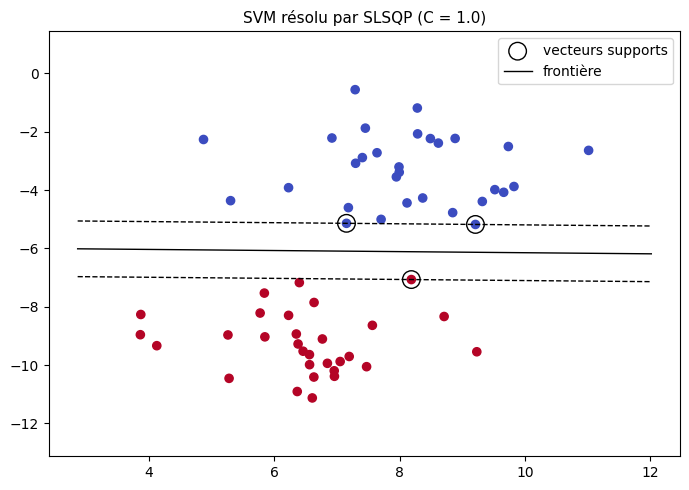

In [6]:
def tracer_svm(ax, X, y, w, b, supports, titre):
    """Points, vecteurs supports, frontière (wᵀx + b = 0) et bords de la marge (wᵀx + b = ±1)."""
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=35)
    ax.scatter(X[supports, 0], X[supports, 1], s=160, facecolors="none", edgecolors="k",
               label="vecteurs supports")
    xx = np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 200)
    for niveau, style, nom in [(0, "-", "frontière"), (1, "--", None), (-1, "--", None)]:
        ax.plot(xx, (niveau - b - w[0] * xx) / w[1], "k" + style, lw=1, label=nom)
    ax.set_ylim(X[:, 1].min() - 2, X[:, 1].max() + 2)
    ax.set_title(titre, fontsize=11)

fig, ax = plt.subplots(figsize=(7, 5))
tracer_svm(ax, X, y, w, b, vect_supports, f"SVM résolu par SLSQP (C = {C})")
ax.legend()
plt.tight_layout()
plt.savefig("svm_resultat.png", dpi=150)
plt.show()

## 6. Rôle de C : Séparable vs non séparable : C = 0.1 et C = 100

séparable (cluster_std = 1.2)       | C = 0.1 | marge = 2.99 |  7 vect. supports |  4 dans la marge |  0 mal classés
séparable (cluster_std = 1.2)       | C = 100 | marge = 1.91 |  3 vect. supports |  0 dans la marge |  0 mal classés
non séparable (cluster_std = 3.0)   | C = 0.1 | marge = 5.12 | 23 vect. supports | 10 dans la marge | 10 mal classés
non séparable (cluster_std = 3.0)   | C = 100 | marge = 3.93 | 21 vect. supports | 10 dans la marge |  9 mal classés


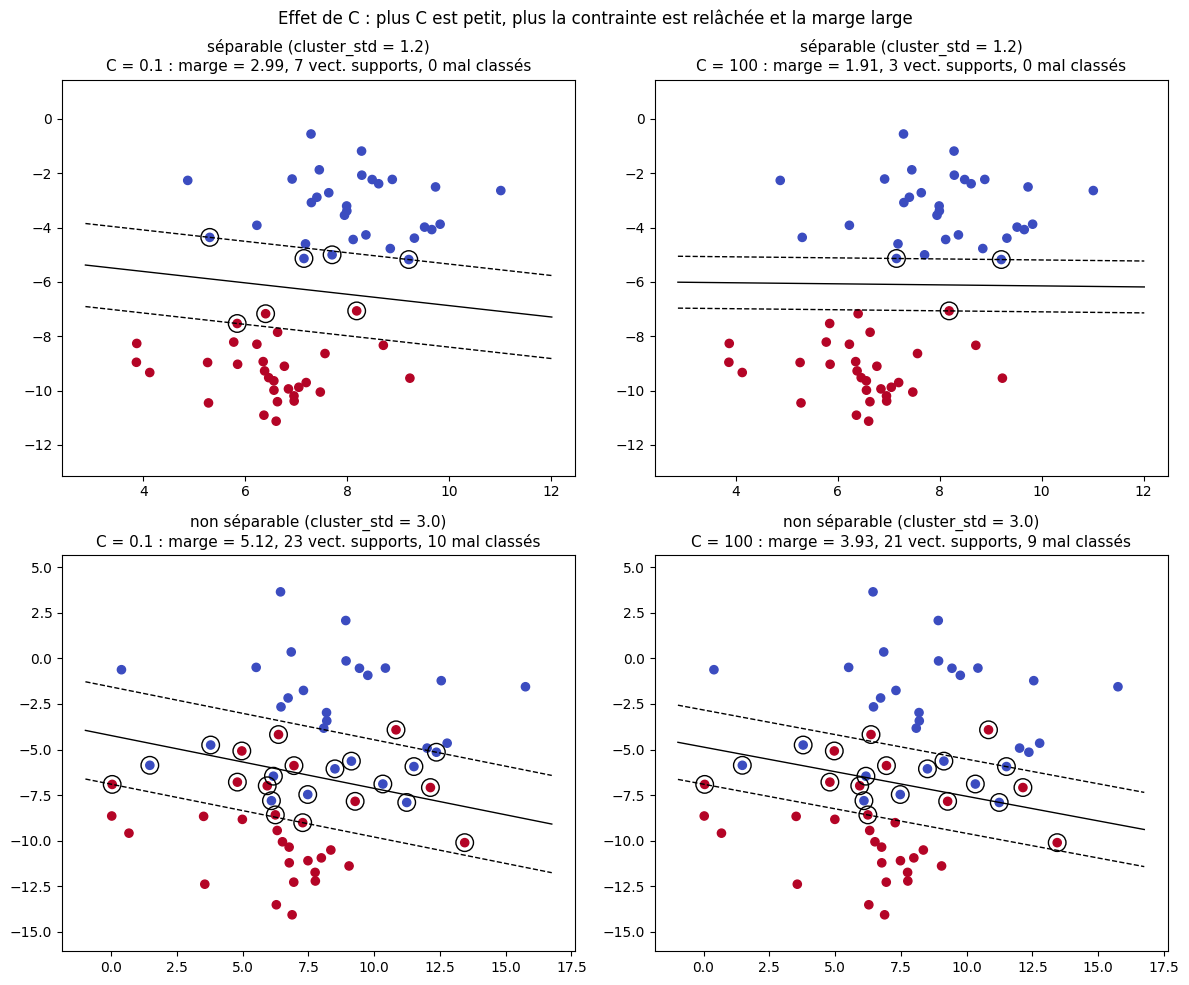

In [9]:
valeurs_C = [0.1, 100]
def largeur_marge(m):  return 2 / np.linalg.norm(m.coef_[0])

cas = {"séparable (cluster_std = 1.2)": 1.2, "non séparable (cluster_std = 3.0)": 3.0}
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ligne, (nom, std) in zip(axes, cas.items()):
    Xc, yc = make_blobs(n_samples=60, centers=2, cluster_std=std, random_state=6)
    yc = np.where(yc == 0, -1.0, 1.0)
    for ax, C_test in zip(ligne, valeurs_C):
        m = SVC(kernel="linear", C=C_test).fit(Xc, yc)
        w_c, b_c, marge = m.coef_[0], m.intercept_[0], largeur_marge(m)
        ξ = np.maximum(0, 1 - yc * (Xc @ w_c + b_c))     # ξᵢ = max(0, 1 − yᵢ(⟨w, xᵢ⟩ + b))
        mal_classes = int((ξ > 1).sum())                 # ξᵢ > 1  ⇔  point mal classé
        dans_marge = int(((ξ > 1e-3) & (ξ <= 1)).sum())  # 0 < ξᵢ ≤ 1  ⇔  dans la marge (seuil numérique)
        print(f"{nom:35s} | C = {C_test:>3} | marge = {marge:.2f} | {len(m.support_):2d} vect. supports"
              f" | {dans_marge:2d} dans la marge | {mal_classes:2d} mal classés")
        tracer_svm(ax, Xc, yc, w_c, b_c, m.support_,
                   f"{nom}\nC = {C_test} : marge = {marge:.2f}, {len(m.support_)} vect. supports, "
                   f"{mal_classes} mal classés")
fig.suptitle("Effet de C : plus C est petit, plus la contrainte est relâchée et la marge large")
plt.tight_layout()
plt.savefig("svm_separable_vs_non.png", dpi=150)
plt.show()